In [2]:
from google.colab import drive
drive.mount('/content/drive')

!pip install -q reportlab

Mounted at /content/drive


In [3]:
import os
from pathlib import Path

PROJECT_ROOT = Path('/content/drive/MyDrive/battery-cycling-quality-analytics')
DOCS_DIR = PROJECT_ROOT / 'docs'
DOCS_DIR.mkdir(parents=True, exist_ok=True)

TEAL = '#008080'
TEAL_LIGHT = '#4DA6A6'
TEAL_DARK  = '#005959'
GREY       = '#4A4A4A'
GREY_LIGHT = '#E8E8E8'

print(f"Docs will be saved to: {DOCS_DIR}")

Docs will be saved to: /content/drive/MyDrive/battery-cycling-quality-analytics/docs


In [4]:
CHARTER = {
    "title": "Capacity Fade Characterization and Quality Control of Lithium-Ion Cells using NASA PCoE Cycling Data",
    "lead": "Bhargava Sriram P",
    "sponsor": "Self-directed",
    "start_date": "October 2026",
    "target_close": "31 January 2027",
    "business_case": (
        "Battery cell manufacturers lose yield and reliability when capacity fade "
        "characteristics vary across cells. A reproducible Six Sigma analysis on NASA PCoE "
        "reference data establishes the measurement and control baseline needed for "
        "high-volume cell production."
    ),
    "problem_statement": (
        "NASA PCoE cells B0005, B0006, B0007, B0018 show capacity fade from approximately "
        "1.85 Ah to below 1.4 Ah (80 percent End-of-Life threshold) over 100 to 170 cycles. "
        "Cell-to-cell variation in this fade behavior is not currently quantified under "
        "Statistical Process Control."
    ),
    "goal_statement": (
        "Quantify capacity fade behavior, establish Statistical Process Control limits, "
        "perform Cp and Cpk capability study, and build a Weibull reliability model. "
        "All deliverables reproducible in both Python and JMP by 31 January 2027."
    ),
    "scope_in": [
        "NASA PCoE cells B0005, B0006, B0007, B0018",
        "Python pipeline (pandas, NumPy, SciPy, matplotlib)",
        "JMP replication of all statistical outputs",
        "DMAIC phases Define, Measure, Analyze, Improve, Control",
    ],
    "scope_out": [
        "Sthyr Energy proprietary zinc-air data (under NDA)",
        "Proprietary industry chemistries (iron-air, nickel-metal hydride, solid-state)",
        "Physical cell cycling or lab experiments",
    ],
    "deliverables": [
        "DMAIC Project Charter, CTQ Tree, SIPOC (Define)",
        "Measurement System Analysis report (Measure)",
        "SPC control charts: X-bar / R and I-MR with Western Electric rules (Analyze)",
        "Pareto, Fishbone, ANOVA on fade drivers (Analyze)",
        "2-squared Design of Experiments on temperature and cutoff voltage (Improve)",
        "Cp / Cpk capability study and Weibull reliability model (Control)",
        "Final report, slide deck, and public GitHub repository",
    ],
    "team": [
        ("Bhargava Sriram P", "Project Lead, Analyst, Author"),
    ],
}

In [5]:
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.units import mm
from reportlab.lib.colors import HexColor
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, KeepTogether
)
from reportlab.lib.enums import TA_LEFT

TEAL_RL = HexColor(TEAL)
GREY_RL = HexColor(GREY_LIGHT)

styles = getSampleStyleSheet()
h_title = ParagraphStyle('h_title', parent=styles['Heading1'],
                         fontSize=14, textColor=TEAL_RL, spaceAfter=4, leading=16)
h_sec   = ParagraphStyle('h_sec', parent=styles['Heading2'],
                         fontSize=9, textColor=TEAL_RL, spaceAfter=2, spaceBefore=4,
                         leading=11, fontName='Helvetica-Bold')
body    = ParagraphStyle('body', parent=styles['BodyText'],
                         fontSize=8, leading=10, alignment=TA_LEFT, spaceAfter=2)
bullet  = ParagraphStyle('bullet', parent=body, leftIndent=10, bulletIndent=0,
                         spaceAfter=1)

charter_pdf = DOCS_DIR / '00_project_charter.pdf'
doc = SimpleDocTemplate(str(charter_pdf), pagesize=A4,
                        leftMargin=14*mm, rightMargin=14*mm,
                        topMargin=12*mm, bottomMargin=12*mm)

story = []
story.append(Paragraph("DMAIC Project Charter", h_title))
story.append(Paragraph(CHARTER["title"], ParagraphStyle(
    'subtitle', parent=body, fontSize=9, textColor=GREY_RL, spaceAfter=6,
    fontName='Helvetica-Oblique')))

meta_rows = [
    ["Project Lead", CHARTER["lead"], "Sponsor", CHARTER["sponsor"]],
    ["Start", CHARTER["start_date"], "Target Close", CHARTER["target_close"]],
]
meta_tbl = Table(meta_rows, colWidths=[25*mm, 55*mm, 25*mm, 55*mm])
meta_tbl.setStyle(TableStyle([
    ('FONTNAME', (0,0), (-1,-1), 'Helvetica'),
    ('FONTSIZE', (0,0), (-1,-1), 8),
    ('TEXTCOLOR', (0,0), (0,-1), TEAL_RL),
    ('TEXTCOLOR', (2,0), (2,-1), TEAL_RL),
    ('FONTNAME', (0,0), (0,-1), 'Helvetica-Bold'),
    ('FONTNAME', (2,0), (2,-1), 'Helvetica-Bold'),
    ('BOTTOMPADDING', (0,0), (-1,-1), 2),
    ('TOPPADDING', (0,0), (-1,-1), 2),
    ('LINEBELOW', (0,-1), (-1,-1), 0.3, TEAL_RL),
]))
story.append(meta_tbl)
story.append(Spacer(1, 4))

def section(title, para_or_list):
    story.append(Paragraph(title, h_sec))
    if isinstance(para_or_list, list):
        for item in para_or_list:
            story.append(Paragraph(f"• {item}", bullet))
    else:
        story.append(Paragraph(para_or_list, body))

section("Business Case", CHARTER["business_case"])
section("Problem Statement", CHARTER["problem_statement"])
section("Goal Statement", CHARTER["goal_statement"])
section("Scope — In", CHARTER["scope_in"])
section("Scope — Out", CHARTER["scope_out"])
section("Deliverables", CHARTER["deliverables"])

story.append(Paragraph("Project Team", h_sec))
team_rows = [["Name", "Role"]] + [[n, r] for n, r in CHARTER["team"]]
team_tbl = Table(team_rows, colWidths=[55*mm, 125*mm])
team_tbl.setStyle(TableStyle([
    ('BACKGROUND', (0,0), (-1,0), TEAL_RL),
    ('TEXTCOLOR',  (0,0), (-1,0), HexColor('#FFFFFF')),
    ('FONTNAME',   (0,0), (-1,0), 'Helvetica-Bold'),
    ('FONTSIZE',   (0,0), (-1,-1), 8),
    ('BOTTOMPADDING', (0,0), (-1,-1), 3),
    ('TOPPADDING', (0,0), (-1,-1), 3),
    ('GRID', (0,0), (-1,-1), 0.25, GREY_RL),
]))
story.append(team_tbl)

doc.build(story)
print(f"Charter PDF saved: {charter_pdf}")

Charter PDF saved: /content/drive/MyDrive/battery-cycling-quality-analytics/docs/00_project_charter.pdf


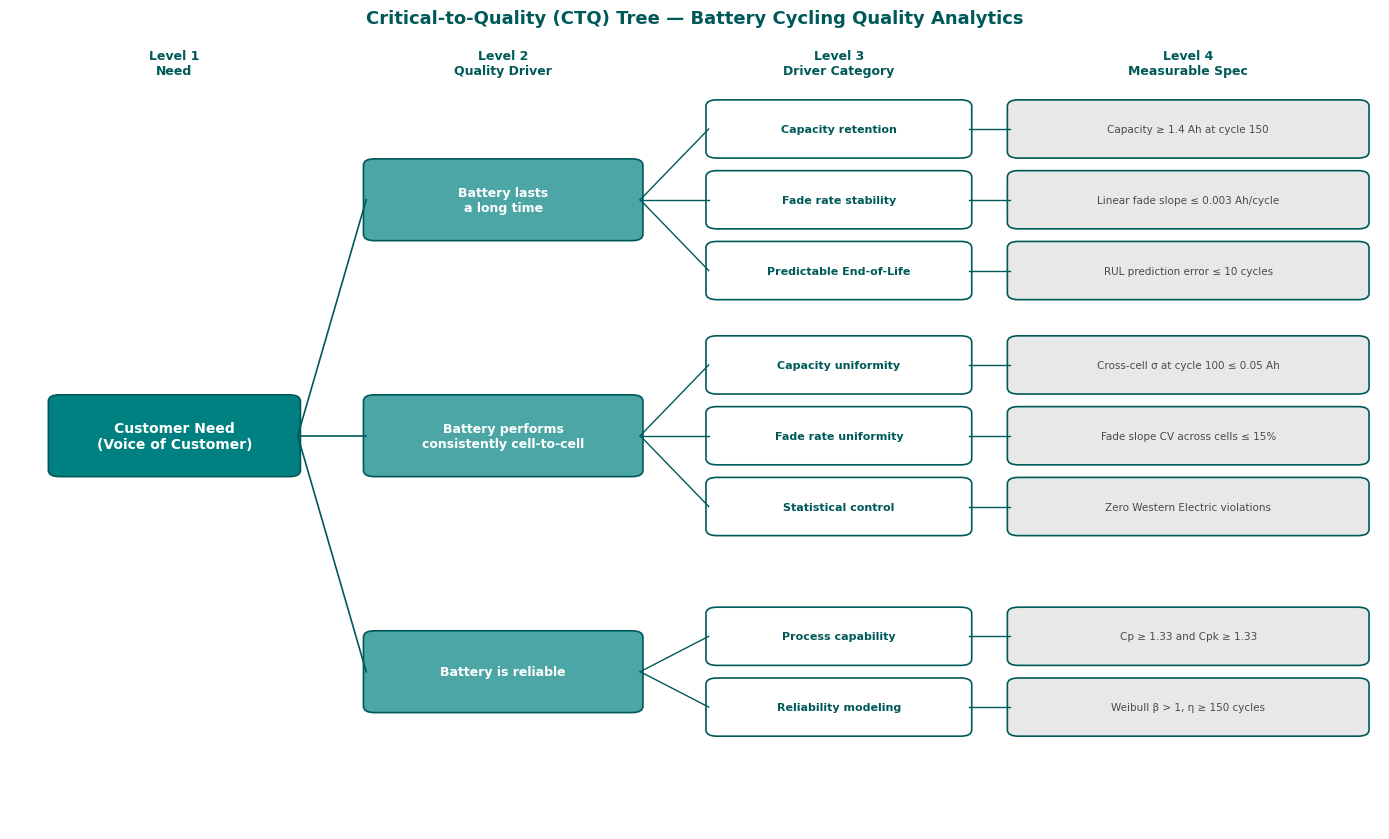

CTQ Tree PNG saved: /content/drive/MyDrive/battery-cycling-quality-analytics/docs/00_ctq_tree.png


In [6]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

ctq_data = {
    "Battery lasts\na long time": [
        ("Capacity retention",       "Capacity ≥ 1.4 Ah at cycle 150"),
        ("Fade rate stability",      "Linear fade slope ≤ 0.003 Ah/cycle"),
        ("Predictable End-of-Life",  "RUL prediction error ≤ 10 cycles"),
    ],
    "Battery performs\nconsistently cell-to-cell": [
        ("Capacity uniformity",      "Cross-cell σ at cycle 100 ≤ 0.05 Ah"),
        ("Fade rate uniformity",     "Fade slope CV across cells ≤ 15%"),
        ("Statistical control",      "Zero Western Electric violations"),
    ],
    "Battery is reliable": [
        ("Process capability",       "Cp ≥ 1.33 and Cpk ≥ 1.33"),
        ("Reliability modeling",     "Weibull β > 1, η ≥ 150 cycles"),
    ],
}

fig, ax = plt.subplots(figsize=(14, 8.5))
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.axis('off')

def box(x, y, w, h, text, fill, text_color='white', fontsize=9, weight='bold'):
    patch = FancyBboxPatch((x, y), w, h,
                           boxstyle="round,pad=0.02,rounding_size=0.08",
                           linewidth=1.2, edgecolor=TEAL_DARK, facecolor=fill)
    ax.add_patch(patch)
    ax.text(x + w/2, y + h/2, text, ha='center', va='center',
            fontsize=fontsize, color=text_color, weight=weight)

box(0.3, 4.5, 1.8, 1.0, "Customer Need\n(Voice of Customer)", TEAL, fontsize=10)

n_needs = len(ctq_data)
need_ys = [8.0, 5.0, 2.0]
for (need, drivers), ny in zip(ctq_data.items(), need_ys):
    box(2.6, ny-0.5, 2.0, 1.0, need, TEAL_LIGHT, fontsize=9)
    ax.plot([2.1, 2.6], [5.0, ny], color=TEAL_DARK, linewidth=1.2)

    n_drivers = len(drivers)
    driver_ys = [ny + (n_drivers-1)/2 * 0.9 - i*0.9 for i in range(n_drivers)]
    for (driver, spec), dy in zip(drivers, driver_ys):
        box(5.1, dy-0.35, 1.9, 0.7, driver, '#FFFFFF',
            text_color=TEAL_DARK, fontsize=8, weight='bold')
        ax.plot([4.6, 5.1], [ny, dy], color=TEAL_DARK, linewidth=1.0)
        box(7.3, dy-0.35, 2.6, 0.7, spec, GREY_LIGHT,
            text_color=GREY, fontsize=7.5, weight='normal')
        ax.plot([7.0, 7.3], [dy, dy], color=TEAL_DARK, linewidth=1.0)

ax.text(1.2, 9.6, "Level 1\nNeed",       ha='center', fontsize=9,
        color=TEAL_DARK, weight='bold')
ax.text(3.6, 9.6, "Level 2\nQuality Driver", ha='center', fontsize=9,
        color=TEAL_DARK, weight='bold')
ax.text(6.05, 9.6, "Level 3\nDriver Category", ha='center', fontsize=9,
        color=TEAL_DARK, weight='bold')
ax.text(8.6, 9.6, "Level 4\nMeasurable Spec",  ha='center', fontsize=9,
        color=TEAL_DARK, weight='bold')

ax.set_title("Critical-to-Quality (CTQ) Tree — Battery Cycling Quality Analytics",
             fontsize=13, color=TEAL_DARK, weight='bold', pad=14)

ctq_png = DOCS_DIR / '00_ctq_tree.png'
plt.tight_layout()
plt.savefig(ctq_png, dpi=200, bbox_inches='tight', facecolor='white')
plt.show()
print(f"CTQ Tree PNG saved: {ctq_png}")

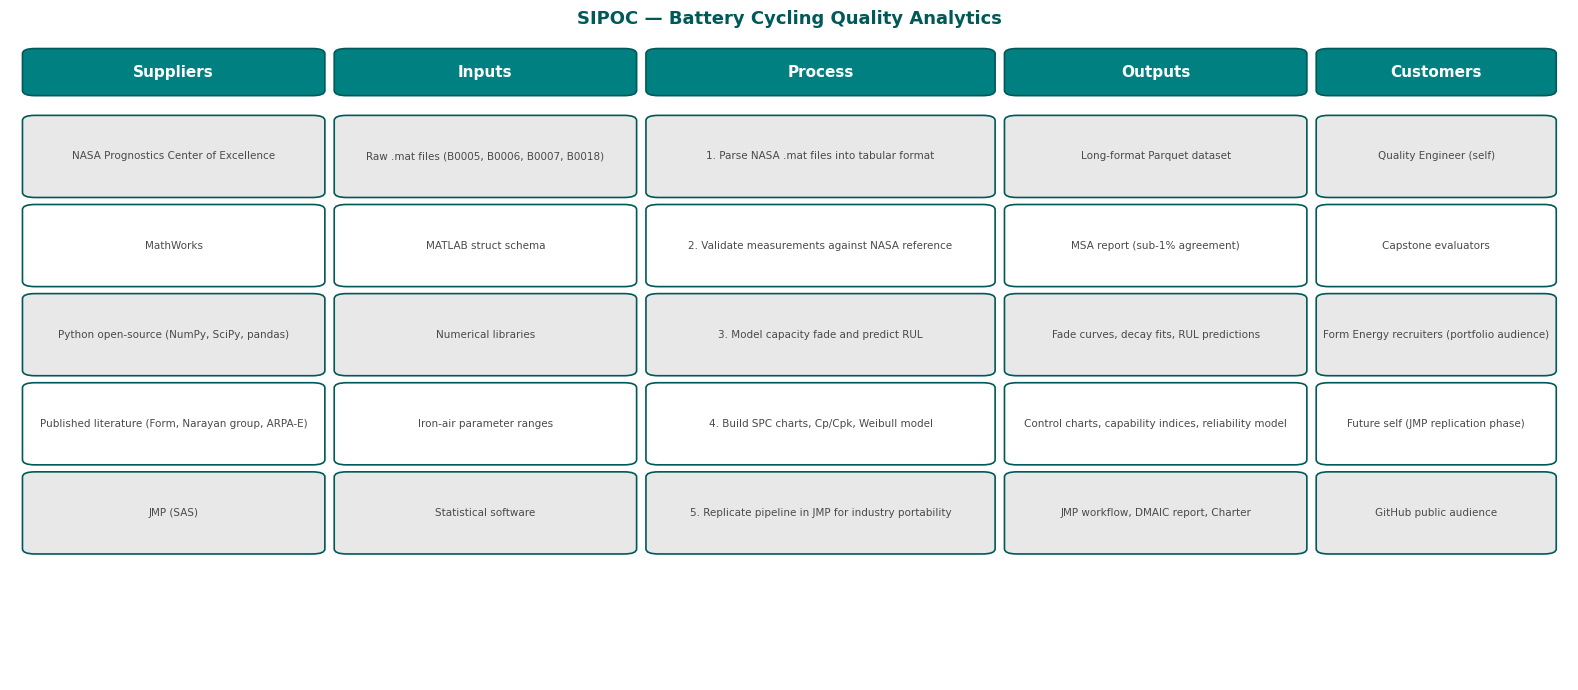

SIPOC PNG saved: /content/drive/MyDrive/battery-cycling-quality-analytics/docs/00_sipoc.png
SIPOC Markdown saved: /content/drive/MyDrive/battery-cycling-quality-analytics/docs/00_sipoc.md


In [7]:
sipoc_rows = [
    ["NASA Prognostics Center of Excellence",
     "Raw .mat files (B0005, B0006, B0007, B0018)",
     "1. Parse NASA .mat files into tabular format",
     "Long-format Parquet dataset",
     "Quality Engineer (self)"],
    ["MathWorks",
     "MATLAB struct schema",
     "2. Validate measurements against NASA reference",
     "MSA report (sub-1% agreement)",
     "Capstone evaluators"],
    ["Python open-source (NumPy, SciPy, pandas)",
     "Numerical libraries",
     "3. Model capacity fade and predict RUL",
     "Fade curves, decay fits, RUL predictions",
     "Form Energy recruiters (portfolio audience)"],
    ["Published literature (Form, Narayan group, ARPA-E)",
     "Iron-air parameter ranges",
     "4. Build SPC charts, Cp/Cpk, Weibull model",
     "Control charts, capability indices, reliability model",
     "Future self (JMP replication phase)"],
    ["JMP (SAS)",
     "Statistical software",
     "5. Replicate pipeline in JMP for industry portability",
     "JMP workflow, DMAIC report, Charter",
     "GitHub public audience"],
]

headers = ["Suppliers", "Inputs", "Process", "Outputs", "Customers"]

fig, ax = plt.subplots(figsize=(16, 7))
ax.axis('off')
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)

col_x = [0.1, 2.1, 4.1, 6.4, 8.4]
col_w = [1.9, 1.9, 2.2, 1.9, 1.5]
header_y = 9.2
header_h = 0.7

for i, (h, x, w) in enumerate(zip(headers, col_x, col_w)):
    box(x, header_y, w, header_h, h, TEAL, fontsize=11)

row_h = 1.4
start_y = header_y - 0.2
for r_idx, row in enumerate(sipoc_rows):
    y = start_y - (r_idx + 1) * row_h
    for c_idx, (cell, x, w) in enumerate(zip(row, col_x, col_w)):
        fill = GREY_LIGHT if r_idx % 2 == 0 else '#FFFFFF'
        box(x, y, w, row_h - 0.15, cell, fill,
            text_color=GREY, fontsize=7.5, weight='normal')

ax.set_title("SIPOC — Battery Cycling Quality Analytics",
             fontsize=13, color=TEAL_DARK, weight='bold', pad=14)

sipoc_png = DOCS_DIR / '00_sipoc.png'
plt.tight_layout()
plt.savefig(sipoc_png, dpi=200, bbox_inches='tight', facecolor='white')
plt.show()
print(f"SIPOC PNG saved: {sipoc_png}")

md_lines = ["# SIPOC — Battery Cycling Quality Analytics", ""]
md_lines.append("| " + " | ".join(headers) + " |")
md_lines.append("|" + "|".join(["---"] * len(headers)) + "|")
for row in sipoc_rows:
    md_lines.append("| " + " | ".join(row) + " |")

sipoc_md = DOCS_DIR / '00_sipoc.md'
sipoc_md.write_text("\n".join(md_lines))
print(f"SIPOC Markdown saved: {sipoc_md}")

In [8]:
for f in ['00_project_charter.pdf', '00_ctq_tree.png', '00_sipoc.png', '00_sipoc.md']:
    p = DOCS_DIR / f
    status = "✓" if p.exists() else "✗ MISSING"
    size = f"{p.stat().st_size/1024:.1f} KB" if p.exists() else "—"
    print(f"{status}  {f:<30} {size}")

✓  00_project_charter.pdf         3.5 KB
✓  00_ctq_tree.png                238.8 KB
✓  00_sipoc.png                   195.6 KB
✓  00_sipoc.md                    1.0 KB
